# Full Model Evaluation — Tiered Metrics

Assumes: 27 tag combos × 5 sequences per model, with precomputed columns:  
`sequence, length, charge, hydrophobicity, frac_basic, frac_acidic, cysteine_count, amp_probability, amp_prediction`

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from collections import Counter
from scipy.stats import entropy, wasserstein_distance
from scorer.scorer import main_scorer
import warnings
warnings.filterwarnings('ignore')

AMINO_ACIDS = list('ACDEFGHIKLMNPQRSTVWY')

DARK_BG = '#0D1117'
CARD_BG = '#161B22'
TEXT = '#E6EDF3'
TEXT_DIM = '#8B949E'
GRID = '#21262D'

MODEL_COLORS = {
    'GPT-2':       '#58A6FF',
    'Transformer': '#79C0FF',
    'LSTM':        '#3FB950',
    'CVAE':        '#BC8CF2',
    'Diffusion':   '#F0883E',
    'MaskGIT':     '#F9826C',
    'EBM':         '#F85149',
    'JEPA':        '#56D4DD',
}

plt.rcParams.update({
    'figure.facecolor': DARK_BG,
    'axes.facecolor': CARD_BG,
    'axes.edgecolor': GRID,
    'axes.labelcolor': TEXT,
    'text.color': TEXT,
    'xtick.color': TEXT_DIM,
    'ytick.color': TEXT_DIM,
    'grid.color': GRID,
    'legend.facecolor': CARD_BG,
    'legend.edgecolor': GRID,
    'font.family': 'sans-serif',
    'font.size': 11,
    'figure.dpi': 150,
})

## 1. Load data

Each model has a CSV with columns:  
`sequence, length, charge, hydrophobicity, frac_basic, frac_acidic, cysteine_count, amp_probability, amp_prediction`  
Plus tag columns: `length_tag, charge_tag, hydro_tag`  

**Edit the paths and the tag column names below.**

In [10]:
TRAIN_CSV = 'data/generator/train_generator_amp_only.csv'
df_train = pd.read_csv(TRAIN_CSV)
df_train = df_train.rename(
    columns={
        'length_bin': 'length_tag',
        'charge_bin': 'charge_tag',
        'hydro_bin': 'hydro_tag',
        'label' : 'amp_prediction'
    }
)
df_train = df_train.drop(columns=[
    'conditioned_text',
    'condition_prefix',
    'is_standard',
    'unique_chars',
    'id'
])

df_train['amp_probability'] = 1

df_train.head()

,sequence,amp_prediction,length,charge,hydrophobicity,frac_basic,frac_acidic,cysteine_count,length_tag,charge_tag,hydro_tag,amp_probability
0,DALAHAHYSPLNNSHCCYCY,1,20,-1,-0.335000,0.000000,0.050000,3,LEN_SHORT,CHARGE_LOW,HYDRO_MED,1
1,QKKIRARLSA,1,10,4,-0.920000,0.400000,0.000000,0,LEN_SHORT,CHARGE_MED,HYDRO_MED,1
2,GAYRAIRHIPRRIR,1,14,5,-0.850000,0.357143,0.000000,0,LEN_SHORT,CHARGE_HIGH,HYDRO_MED,1
3,RRGRIGRNPSQVGD,1,14,3,-1.671429,0.285714,0.071429,0,LEN_SHORT,CHARGE_MED,HYDRO_LOW,1
4,GIFSKFAGKGIKNLLVKGVKNIGKEVGMDVIRTGIDIAGCKIKGEC,1,46,5,0.221739,0.195652,0.086957,2,LEN_LONG,CHARGE_HIGH,HYDRO_MED,1


In [21]:
MODELS = ['gpt_2', 'transformer', 'lstm', 'cvae', 'diffusion', 'maskgit', 'ebm', 'jepa']
GENERATED_PATHS = {model: f'./logs/generation_{model}.csv' for model in MODELS}
GENERATED = {}
for model, path in GENERATED_PATHS.items():
    df_gen = pd.read_csv(path)
    obj_cols = df_gen.select_dtypes(include='object').columns
    df_gen[obj_cols] = df_gen[obj_cols].apply(
        lambda col: col.str.replace('<', '', regex=False).str.replace('>', '', regex=False).str.strip()
    )
    GENERATED[model] = df_gen


SCORES = {}

for model in MODELS:
    scores = main_scorer(GENERATED[model]['sequence'])

    tags = GENERATED[model][['sequence', 'length_tag', 'charge_tag', 'hydro_tag']] \
        .drop_duplicates(subset='sequence')

    scores = scores.merge(tags, on='sequence', how='left')
    SCORES[model] = scores
    
SCORES['baseline'] = df_train
# optional quick check
for model, df_scores in SCORES.items():
    print(f"{model}: {df_scores.shape}")

gpt_2: (270, 12)
transformer: (270, 12)
lstm: (270, 12)
cvae: (270, 12)
diffusion: (270, 12)
maskgit: (270, 12)
ebm: (270, 12)
jepa: (270, 12)
baseline: (23791, 12)


In [22]:
# Save the full SCORES dictionary (all model DataFrames) into one file
scores_path = "./logs/scores_all_models.pkl"
pd.to_pickle(SCORES, scores_path)

print(f"Saved SCORES to: {scores_path}")
print(f"Keys: {list(SCORES.keys())}")

Saved SCORES to: ./logs/scores_all_models.pkl
Keys: ['gpt_2', 'transformer', 'lstm', 'cvae', 'diffusion', 'maskgit', 'ebm', 'jepa', 'baseline']


In [23]:
# Reuse data prepared in previous cells
TAG_LEN_COL   = 'length_tag'
TAG_CHG_COL   = 'charge_tag'
TAG_HYDRO_COL = 'hydro_tag'

# baseline (real) data
real_df = SCORES['baseline'].copy()

# map display names -> keys used in SCORES
score_key_map = {
    'GPT-2': 'gpt_2',
    'Transformer': 'transformer',
    'LSTM': 'lstm',
    'CVAE': 'cvae',
    'Diffusion': 'diffusion',
    'MaskGIT': 'maskgit',
    'EBM': 'ebm',
    'JEPA': 'jepa',
}

def _ensure_bracket_tag(x):
    if pd.isna(x):
        return x
    s = str(x).strip().replace('<', '').replace('>', '')
    return f'<{s}>'

# model dataframes for evaluation
model_dfs = {}
for display_name, score_key in score_key_map.items():
    if score_key in SCORES:
        df = SCORES[score_key].copy()

        # normalize tag value format for downstream TAG_BIN_MAP matching
        for c in [TAG_LEN_COL, TAG_CHG_COL, TAG_HYDRO_COL]:
            if c in df.columns:
                df[c] = df[c].map(_ensure_bracket_tag)
        model_dfs[display_name] = df
        print(f'{display_name:12s}: {len(df)} sequences loaded from SCORES[{score_key!r}]')
    else:
        print(f'{display_name:12s}: missing key in SCORES -> {score_key!r}')

# normalize real_df tags too (if present)
for c in [TAG_LEN_COL, TAG_CHG_COL, TAG_HYDRO_COL]:
    if c in real_df.columns:
        real_df[c] = real_df[c].map(_ensure_bracket_tag)

MODEL_NAMES = list(model_dfs.keys())
print(f'Real: {len(real_df)} sequences')

GPT-2       : 270 sequences loaded from SCORES['gpt_2']
Transformer : 270 sequences loaded from SCORES['transformer']
LSTM        : 270 sequences loaded from SCORES['lstm']
CVAE        : 270 sequences loaded from SCORES['cvae']
Diffusion   : 270 sequences loaded from SCORES['diffusion']
MaskGIT     : 270 sequences loaded from SCORES['maskgit']
EBM         : 270 sequences loaded from SCORES['ebm']
JEPA        : 270 sequences loaded from SCORES['jepa']
Real: 23791 sequences


## 2. Compute tag bin boundaries from training data

We derive the bin edges from the training set's tertile splits so we can check if generated sequences land in the correct bin.

In [24]:
# compute tertile boundaries from training data
def compute_bins(series):
    t1 = series.quantile(1/3)
    t2 = series.quantile(2/3)
    return t1, t2

len_t1, len_t2 = compute_bins(real_df['length'])
chg_t1, chg_t2 = compute_bins(real_df['charge'])
hyd_t1, hyd_t2 = compute_bins(real_df['hydrophobicity'])

print(f'Length bins:        SHORT < {len_t1:.1f} | MED < {len_t2:.1f} | LONG')
print(f'Charge bins:        LOW   < {chg_t1:.1f} | MED < {chg_t2:.1f} | HIGH')
print(f'Hydrophobicity bins: LOW  < {hyd_t1:.3f} | MED < {hyd_t2:.3f} | HIGH')

TAG_BIN_MAP = {
    TAG_LEN_COL: {
        '<LEN_SHORT>': (-np.inf, len_t1),
        '<LEN_MED>':   (len_t1, len_t2),
        '<LEN_LONG>':  (len_t2, np.inf),
    },
    TAG_CHG_COL: {
        '<CHARGE_LOW>':  (-np.inf, chg_t1),
        '<CHARGE_MED>':  (chg_t1, chg_t2),
        '<CHARGE_HIGH>': (chg_t2, np.inf),
    },
    TAG_HYDRO_COL: {
        '<HYDRO_LOW>':  (-np.inf, hyd_t1),
        '<HYDRO_MED>':  (hyd_t1, hyd_t2),
        '<HYDRO_HIGH>': (hyd_t2, np.inf),
    },
}

PROPERTY_COL_FOR_TAG = {
    TAG_LEN_COL:   'length',
    TAG_CHG_COL:   'charge',
    TAG_HYDRO_COL: 'hydrophobicity',
}

Length bins:        SHORT < 17.0 | MED < 21.0 | LONG
Charge bins:        LOW   < 1.0 | MED < 4.0 | HIGH
Hydrophobicity bins: LOW  < -0.590 | MED < 0.130 | HIGH


## 3. Tier 1 — Does it work?

In [25]:
def tier1_metrics(df):
    n = len(df)
    amp_hit_rate = df['amp_prediction'].mean()
    valid_aa_rate = df['sequence'].apply(
        lambda s: all(c in AMINO_ACIDS for c in str(s))
    ).mean()
    return {
        'AMP Hit Rate': amp_hit_rate,
        'Valid AA Rate': valid_aa_rate,
    }

tier1 = {name: tier1_metrics(df) for name, df in model_dfs.items()}
tier1_df = pd.DataFrame(tier1).T
tier1_df.style.format('{:.3f}').background_gradient(cmap='RdYlGn', subset=['AMP Hit Rate'])

,AMP Hit Rate,Valid AA Rate
GPT-2,0.756,1.000
Transformer,0.837,1.000
LSTM,0.778,1.000
CVAE,0.700,1.000
Diffusion,0.726,1.000
MaskGIT,0.804,1.000
EBM,0.989,1.000
JEPA,0.944,1.000


## 4. Tier 2 — Does it respect the tags?

In [26]:
def tag_adherence(df, tag_col, prop_col, bin_map):
    """For each row, check if the generated property falls in the bin requested by the tag."""
    correct = 0
    total = 0
    for _, row in df.iterrows():
        tag = row[tag_col]
        if tag not in bin_map:
            continue
        lo, hi = bin_map[tag]
        val = row[prop_col]
        if lo <= val < hi:
            correct += 1
        total += 1
    return correct / max(total, 1)


def tier2_metrics(df):
    results = {}
    for tag_col, bin_map in TAG_BIN_MAP.items():
        prop_col = PROPERTY_COL_FOR_TAG[tag_col]
        label = prop_col.capitalize() + ' Match'
        results[label] = tag_adherence(df, tag_col, prop_col, bin_map)

    results['Mean Tag Adherence'] = np.mean(list(results.values()))

    # mean AMP probability across all 27 tag combos
    if TAG_LEN_COL in df.columns:
        combo_means = df.groupby([TAG_LEN_COL, TAG_CHG_COL, TAG_HYDRO_COL])['amp_probability'].mean()
        results['Min Combo P(AMP)'] = combo_means.min()
        results['Mean Combo P(AMP)'] = combo_means.mean()
    return results


tier2 = {name: tier2_metrics(df) for name, df in model_dfs.items()}
tier2_df = pd.DataFrame(tier2).T
tier2_df.style.format('{:.3f}').background_gradient(cmap='RdYlGn')

,Length Match,Charge Match,Hydrophobicity Match,Mean Tag Adherence,Min Combo P(AMP),Mean Combo P(AMP)
GPT-2,0.533,0.693,0.778,0.668,0.238,0.739
Transformer,0.544,0.722,0.819,0.695,0.306,0.810
LSTM,0.570,0.748,0.785,0.701,0.249,0.745
CVAE,0.611,0.719,0.819,0.716,0.279,0.661
Diffusion,0.796,0.459,0.574,0.610,0.189,0.674
MaskGIT,0.693,0.685,0.774,0.717,0.210,0.730
EBM,1.000,0.707,0.696,0.801,0.580,0.903
JEPA,1.000,0.630,0.707,0.779,0.458,0.873


## 5. Tier 3 — Does it produce good AMPs?

In [27]:
def aa_frequency_vec(sequences):
    all_aa = ''.join(str(s) for s in sequences)
    counts = Counter(all_aa)
    total = sum(counts[aa] for aa in AMINO_ACIDS)
    if total == 0:
        return np.ones(20) / 20
    return np.array([counts.get(aa, 0) / total for aa in AMINO_ACIDS])


def bigram_frequency_vec(sequences):
    all_bigrams = []
    for s in sequences:
        s = str(s)
        all_bigrams.extend(s[i:i+2] for i in range(len(s)-1))
    counts = Counter(all_bigrams)
    all_keys = sorted(a+b for a in AMINO_ACIDS for b in AMINO_ACIDS)
    total = sum(counts.get(k, 0) for k in all_keys)
    if total == 0:
        return np.ones(400) / 400
    return np.array([counts.get(k, 0) / total for k in all_keys])


def kl_safe(p, q):
    """KL(p || q) with smoothing."""
    p = p + 1e-10
    q = q + 1e-10
    p = p / p.sum()
    q = q / q.sum()
    return entropy(p, q)


# precompute real distributions
real_aa_vec = aa_frequency_vec(real_df['sequence'])
real_bigram_vec = bigram_frequency_vec(real_df['sequence'])


def tier3_metrics(df):
    results = {}

    results['Mean P(AMP)'] = df['amp_probability'].mean()
    results['Median P(AMP)'] = df['amp_probability'].median()
    results['P(AMP) > 0.8'] = (df['amp_probability'] > 0.8).mean()

    # KL divergences
    gen_aa = aa_frequency_vec(df['sequence'])
    gen_bigram = bigram_frequency_vec(df['sequence'])
    results['KL AA vs Real'] = kl_safe(gen_aa, real_aa_vec)
    results['KL Bigram vs Real'] = kl_safe(gen_bigram, real_bigram_vec)

    # distributional match for key properties
    for col in ['frac_basic', 'frac_acidic', 'cysteine_count', 'charge', 'hydrophobicity']:
        if col in df.columns and col in real_df.columns:
            w = wasserstein_distance(df[col].dropna(), real_df[col].dropna())
            results[f'Wass({col})'] = w

    return results


tier3 = {name: tier3_metrics(df) for name, df in model_dfs.items()}
tier3_df = pd.DataFrame(tier3).T
tier3_df.style.format('{:.4f}').background_gradient(
    cmap='RdYlGn',
    subset=['Mean P(AMP)', 'Median P(AMP)', 'P(AMP) > 0.8']
).background_gradient(
    cmap='RdYlGn_r',
    subset=[c for c in tier3_df.columns if 'KL' in c or 'Wass' in c]
)

,Mean P(AMP),Median P(AMP),P(AMP) > 0.8,KL AA vs Real,KL Bigram vs Real,Wass(frac_basic),Wass(frac_acidic),Wass(cysteine_count),Wass(charge),Wass(hydrophobicity)
GPT-2,0.7393,0.9139,0.5889,0.0133,0.0726,0.0117,0.0119,0.1239,0.6551,0.3441
Transformer,0.8107,0.9667,0.7148,0.0172,0.0929,0.0142,0.0052,0.2225,0.3517,0.2927
LSTM,0.7448,0.8952,0.6111,0.0129,0.0703,0.0134,0.0061,0.3214,0.5097,0.3418
CVAE,0.6607,0.7384,0.4333,0.0087,0.0686,0.0115,0.0142,0.2775,0.3895,0.1661
Diffusion,0.6743,0.7785,0.4630,0.0126,0.1019,0.0430,0.0109,0.5272,0.9810,0.4167
MaskGIT,0.7298,0.8245,0.5296,0.0135,0.0725,0.0144,0.0058,0.1831,0.3603,0.2255
EBM,0.9017,0.9633,0.8000,0.0693,0.3228,0.0253,0.0216,0.2925,0.3985,0.3578
JEPA,0.8729,0.9521,0.7667,0.1006,0.3022,0.0314,0.0225,0.3777,0.9562,0.4263


## 6. Tier 4 — Diversity & novelty

In [28]:
def edit_distance_norm(s1, s2):
    s1, s2 = str(s1), str(s2)
    max_l = max(len(s1), len(s2))
    if max_l == 0:
        return 0.0
    diffs = sum(1 for a, b in zip(s1, s2) if a != b)
    diffs += abs(len(s1) - len(s2))
    return diffs / max_l


def tier4_metrics(df, real_sequences_set):
    seqs = df['sequence'].astype(str).tolist()
    n = len(seqs)
    results = {}

    # AA entropy
    aa_vec = aa_frequency_vec(seqs)
    results['AA Entropy'] = entropy(aa_vec + 1e-10) / np.log(20)

    # sequence diversity (pairwise edit distance)
    if n > 1:
        dists = []
        # subsample for speed if many sequences
        sample = seqs if n <= 200 else list(np.random.choice(seqs, 200, replace=False))
        for i in range(len(sample)):
            for j in range(i+1, len(sample)):
                dists.append(edit_distance_norm(sample[i], sample[j]))
        results['Seq Diversity'] = np.mean(dists)
    else:
        results['Seq Diversity'] = 0.0

    # unique fraction
    results['Unique Frac'] = len(set(seqs)) / max(n, 1)

    # novelty
    results['Novelty Rate'] = sum(1 for s in seqs if s not in real_sequences_set) / max(n, 1)

    return results


real_seq_set = set(real_df['sequence'].astype(str).tolist())
tier4 = {name: tier4_metrics(df, real_seq_set) for name, df in model_dfs.items()}
tier4_df = pd.DataFrame(tier4).T
tier4_df.style.format('{:.4f}').background_gradient(cmap='RdYlGn')

,AA Entropy,Seq Diversity,Unique Frac,Novelty Rate
GPT-2,0.9547,0.9523,0.9889,0.8630
Transformer,0.9470,0.9497,0.9519,0.7926
LSTM,0.9498,0.9520,0.9926,0.9296
CVAE,0.9546,0.9549,1.0000,1.0000
Diffusion,0.9490,0.9523,1.0000,1.0000
MaskGIT,0.9679,0.9544,1.0000,1.0000
EBM,0.9069,0.9343,0.8333,0.8333
JEPA,0.8736,0.9275,0.9889,0.9667


## 7. Positional frequency divergence

In [29]:
from scipy.spatial.distance import jensenshannon

def positional_freq(sequences, max_pos=30):
    mat = np.zeros((20, max_pos))
    totals = np.zeros(max_pos)
    aa_idx = {aa: i for i, aa in enumerate(AMINO_ACIDS)}
    for s in sequences:
        s = str(s)
        for i, c in enumerate(s[:max_pos]):
            if c in aa_idx:
                mat[aa_idx[c], i] += 1
                totals[i] += 1
    totals[totals == 0] = 1
    return mat / totals[np.newaxis, :]


MAX_POS = 30
real_pos_freq = positional_freq(real_df['sequence'], MAX_POS)

pos_div = {}
for name, df in model_dfs.items():
    gen_pos_freq = positional_freq(df['sequence'], MAX_POS)
    js_per_pos = []
    for i in range(MAX_POS):
        p = real_pos_freq[:, i] + 1e-10
        q = gen_pos_freq[:, i] + 1e-10
        js_per_pos.append(jensenshannon(p, q))
    pos_div[name] = {
        'Mean Pos JS': np.mean(js_per_pos),
        'Max Pos JS': np.max(js_per_pos),
    }

pos_div_df = pd.DataFrame(pos_div).T
pos_div_df.style.format('{:.4f}').background_gradient(cmap='RdYlGn_r')

,Mean Pos JS,Max Pos JS
GPT-2,0.1347,0.1885
Transformer,0.1525,0.1990
LSTM,0.1395,0.2017
CVAE,0.1442,0.2388
Diffusion,0.1599,0.2503
MaskGIT,0.1571,0.2462
EBM,0.2516,0.3375
JEPA,0.2387,0.3448


## 8. Visualizations

### 8a. AMP probability violins — the single most important plot

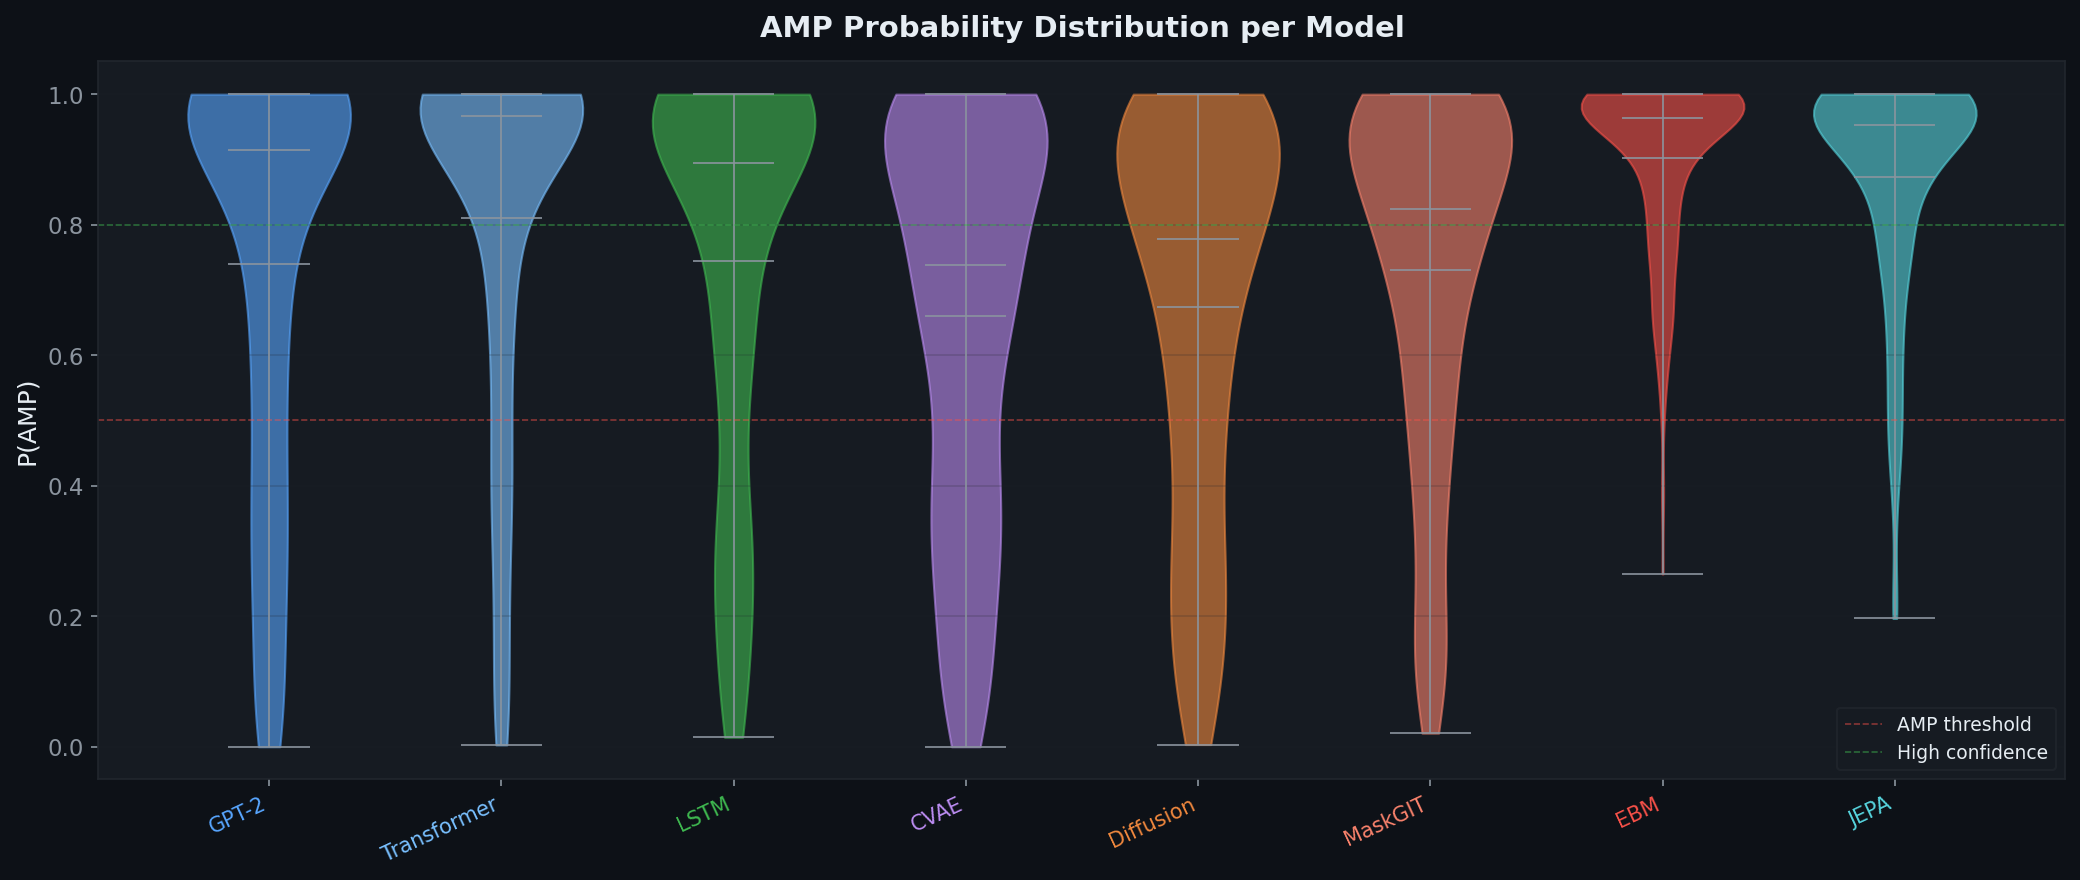

In [30]:
fig, ax = plt.subplots(figsize=(14, 6))

positions = range(len(MODEL_NAMES))
violins_data = [model_dfs[m]['amp_probability'].dropna().values for m in MODEL_NAMES]

parts = ax.violinplot(violins_data, positions=positions, showmeans=True,
                      showmedians=True, widths=0.7)

for i, pc in enumerate(parts['bodies']):
    color = MODEL_COLORS[MODEL_NAMES[i]]
    pc.set_facecolor(color)
    pc.set_alpha(0.6)
    pc.set_edgecolor(color)

for key in ['cmeans', 'cmedians', 'cbars', 'cmins', 'cmaxes']:
    parts[key].set_color(TEXT_DIM)
    parts[key].set_linewidth(0.8)

ax.axhline(0.5, color='#F85149', linewidth=0.8, linestyle='--', alpha=0.5, label='AMP threshold')
ax.axhline(0.8, color='#3FB950', linewidth=0.8, linestyle='--', alpha=0.5, label='High confidence')

ax.set_xticks(positions)
ax.set_xticklabels(MODEL_NAMES, fontsize=10, rotation=25, ha='right')
for i, m in enumerate(MODEL_NAMES):
    ax.get_xticklabels()[i].set_color(MODEL_COLORS[m])

ax.set_ylabel('P(AMP)', fontsize=12)
ax.set_ylim(-0.05, 1.05)
ax.set_title('AMP Probability Distribution per Model', fontsize=14, fontweight='bold', pad=12)
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.savefig('amp_probability_violins.png', dpi=300, bbox_inches='tight', facecolor=DARK_BG)
plt.show()

### 8b. Tag adherence heatmap

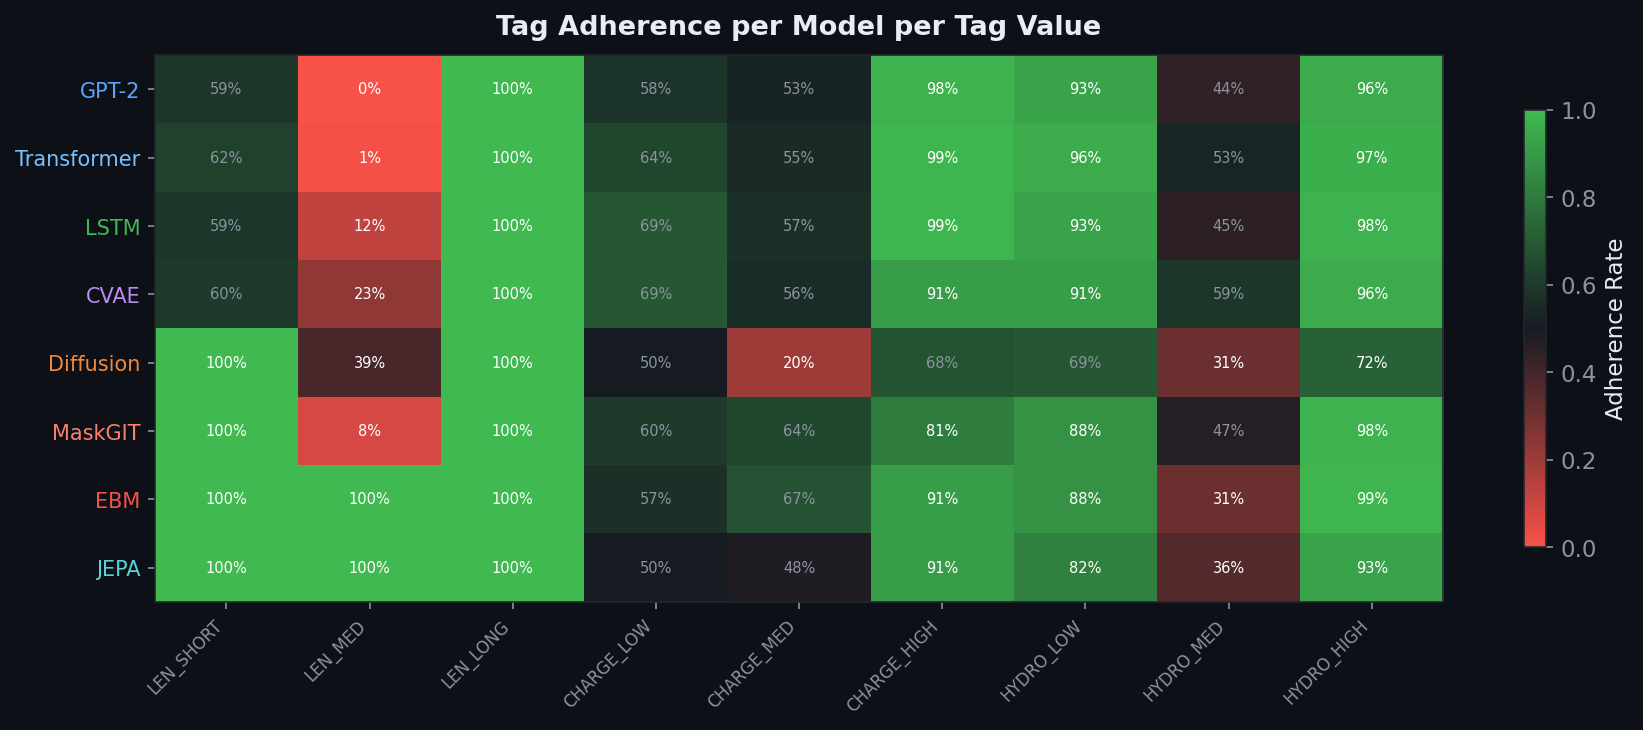

In [31]:
# build adherence per model per property
adh_data = {}
prop_labels = []
for tag_col, bin_map in TAG_BIN_MAP.items():
    prop_col = PROPERTY_COL_FOR_TAG[tag_col]
    for tag_val in bin_map:
        label = tag_val.replace('<','').replace('>','')
        prop_labels.append(label)
        for name, df in model_dfs.items():
            subset = df[df[tag_col] == tag_val]
            if len(subset) == 0:
                adh_data.setdefault(name, []).append(0)
                continue
            lo, hi = bin_map[tag_val]
            frac = ((subset[prop_col] >= lo) & (subset[prop_col] < hi)).mean()
            adh_data.setdefault(name, []).append(frac)

adh_matrix = np.array([adh_data[m] for m in MODEL_NAMES])

fig, ax = plt.subplots(figsize=(12, 5))
cmap = LinearSegmentedColormap.from_list('adh', ['#F85149', '#161B22', '#3FB950'])
im = ax.imshow(adh_matrix, aspect='auto', cmap=cmap, vmin=0, vmax=1)

ax.set_xticks(range(len(prop_labels)))
ax.set_xticklabels(prop_labels, fontsize=8, rotation=45, ha='right')
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels(MODEL_NAMES, fontsize=10)
for i, m in enumerate(MODEL_NAMES):
    ax.get_yticklabels()[i].set_color(MODEL_COLORS[m])

# annotate with values
for i in range(len(MODEL_NAMES)):
    for j in range(len(prop_labels)):
        val = adh_matrix[i, j]
        color = 'white' if val < 0.4 or val > 0.7 else TEXT_DIM
        ax.text(j, i, f'{val:.0%}', ha='center', va='center', fontsize=7, color=color)

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Adherence Rate', color=TEXT)

ax.set_title('Tag Adherence per Model per Tag Value', fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig('tag_adherence_heatmap.png', dpi=300, bbox_inches='tight', facecolor=DARK_BG)
plt.show()

### 8c. frac_basic vs frac_acidic scatter

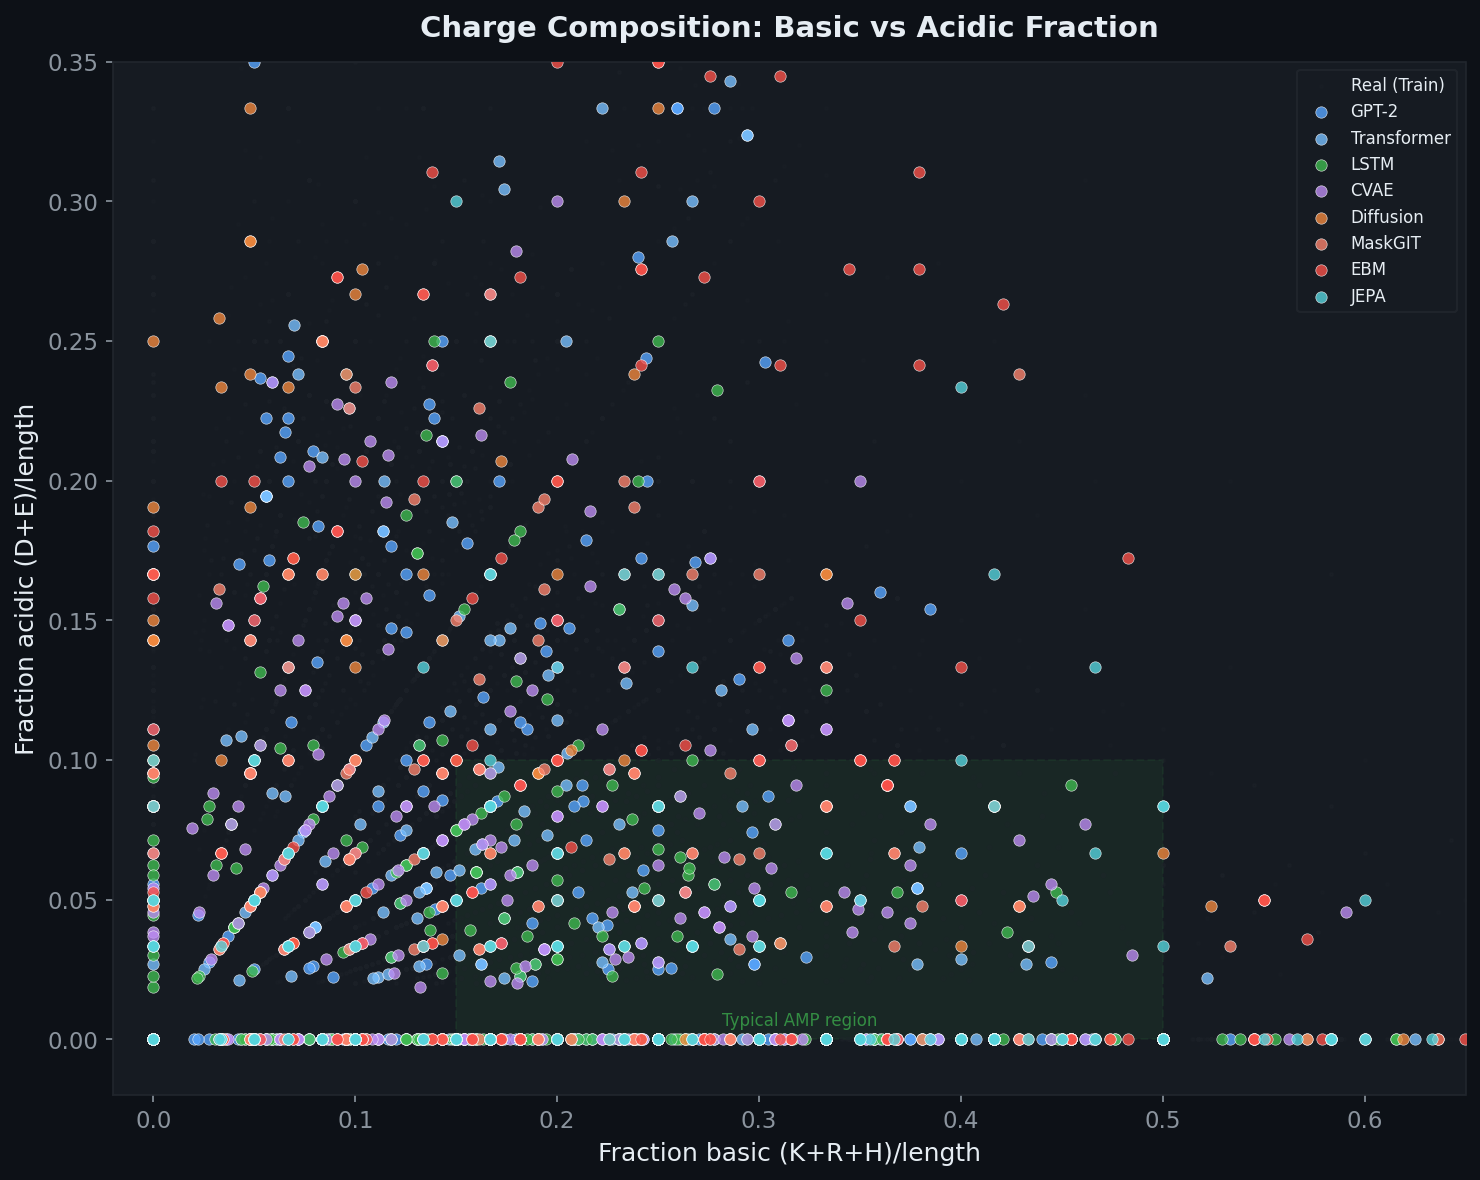

In [32]:
fig, ax = plt.subplots(figsize=(10, 8))

# real as background
ax.scatter(real_df['frac_basic'], real_df['frac_acidic'],
           c='#21262D', s=3, alpha=0.15, label='Real (Train)', zorder=1)

for name in MODEL_NAMES:
    df = model_dfs[name]
    color = MODEL_COLORS[name]
    ax.scatter(df['frac_basic'], df['frac_acidic'],
              c=color, s=30, alpha=0.8, label=name,
              edgecolors='white', linewidth=0.3, zorder=3)

# AMP region annotation
from matplotlib.patches import Rectangle
amp_box = Rectangle((0.15, 0), 0.35, 0.10, linewidth=1,
                     edgecolor='#3FB950', facecolor='#3FB950',
                     alpha=0.08, linestyle='--', zorder=0)
ax.add_patch(amp_box)
ax.text(0.32, 0.005, 'Typical AMP region', fontsize=8,
        color='#3FB950', alpha=0.7, ha='center')

ax.set_xlabel('Fraction basic (K+R+H)/length', fontsize=12)
ax.set_ylabel('Fraction acidic (D+E)/length', fontsize=12)
ax.set_title('Charge Composition: Basic vs Acidic Fraction', fontsize=14,
             fontweight='bold', pad=12)
ax.legend(fontsize=8, loc='upper right', framealpha=0.9)
ax.set_xlim(-0.02, 0.65)
ax.set_ylim(-0.02, 0.35)

plt.tight_layout()
plt.savefig('basic_vs_acidic_scatter.png', dpi=300, bbox_inches='tight', facecolor=DARK_BG)
plt.show()

### 8d. Cysteine count distribution

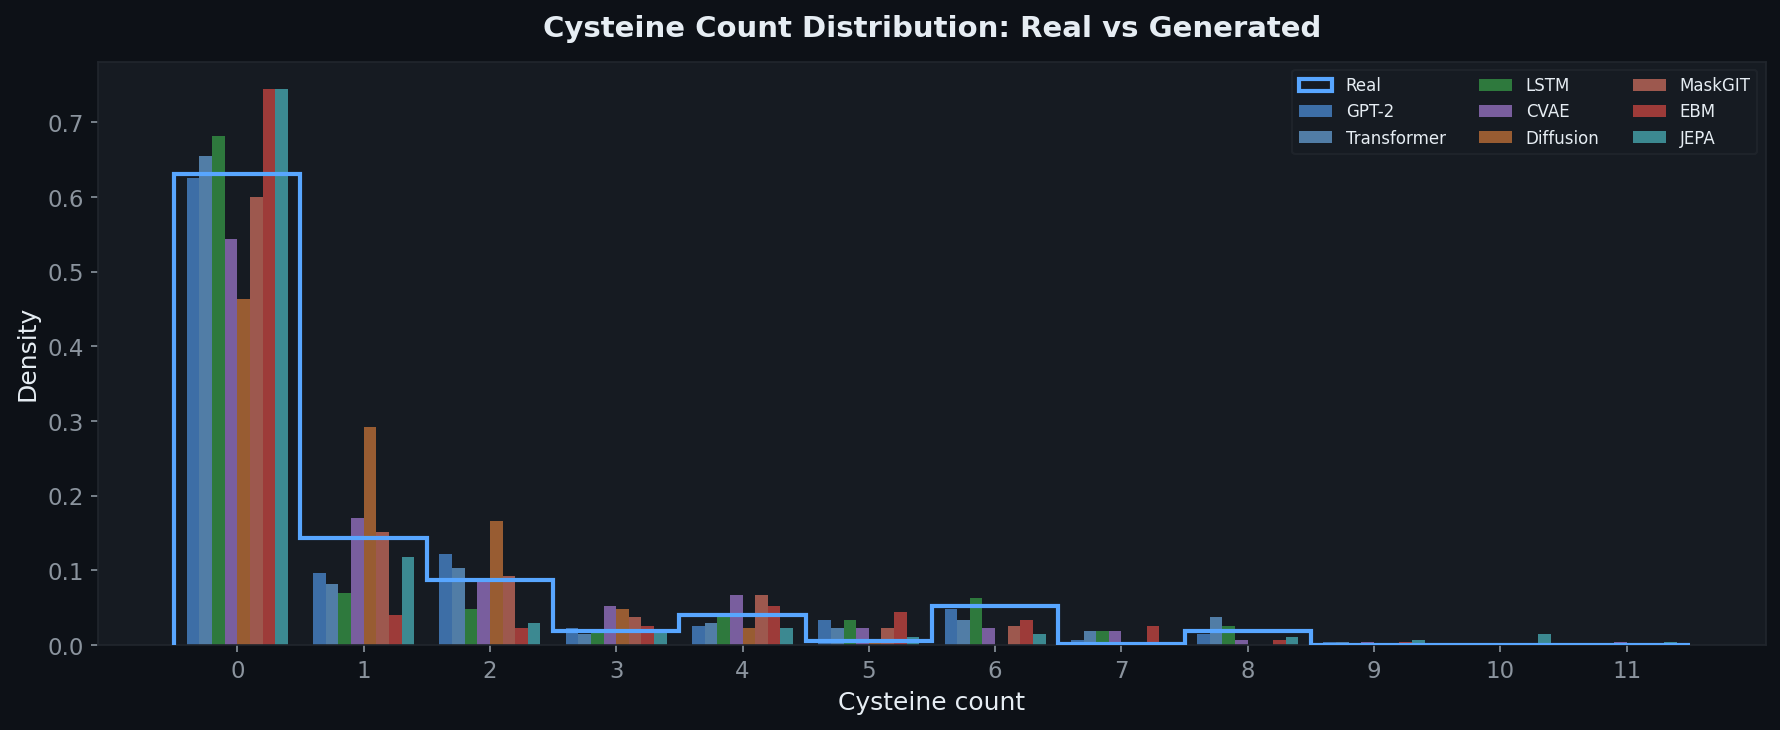

In [33]:
fig, ax = plt.subplots(figsize=(12, 5))

max_cys = int(max(real_df['cysteine_count'].max(), max(df['cysteine_count'].max() for df in model_dfs.values())))
bins = np.arange(-0.5, max_cys + 1.5, 1)

# real as outline
ax.hist(real_df['cysteine_count'], bins=bins, density=True,
        histtype='step', linewidth=2, color='#58A6FF', label='Real', zorder=10)

bar_width = 0.8 / len(MODEL_NAMES)
for i, name in enumerate(MODEL_NAMES):
    df = model_dfs[name]
    counts, _ = np.histogram(df['cysteine_count'], bins=bins, density=True)
    x = np.arange(max_cys + 1) + i * bar_width - 0.4 + bar_width/2
    ax.bar(x, counts, width=bar_width, color=MODEL_COLORS[name],
           alpha=0.6, label=name)

ax.set_xlabel('Cysteine count', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Cysteine Count Distribution: Real vs Generated', fontsize=14,
             fontweight='bold', pad=12)
ax.legend(fontsize=8, ncol=3)
ax.set_xticks(range(max_cys + 1))

plt.tight_layout()
plt.savefig('cysteine_distribution.png', dpi=300, bbox_inches='tight', facecolor=DARK_BG)
plt.show()

### 8e. Radar chart — multi-metric comparison

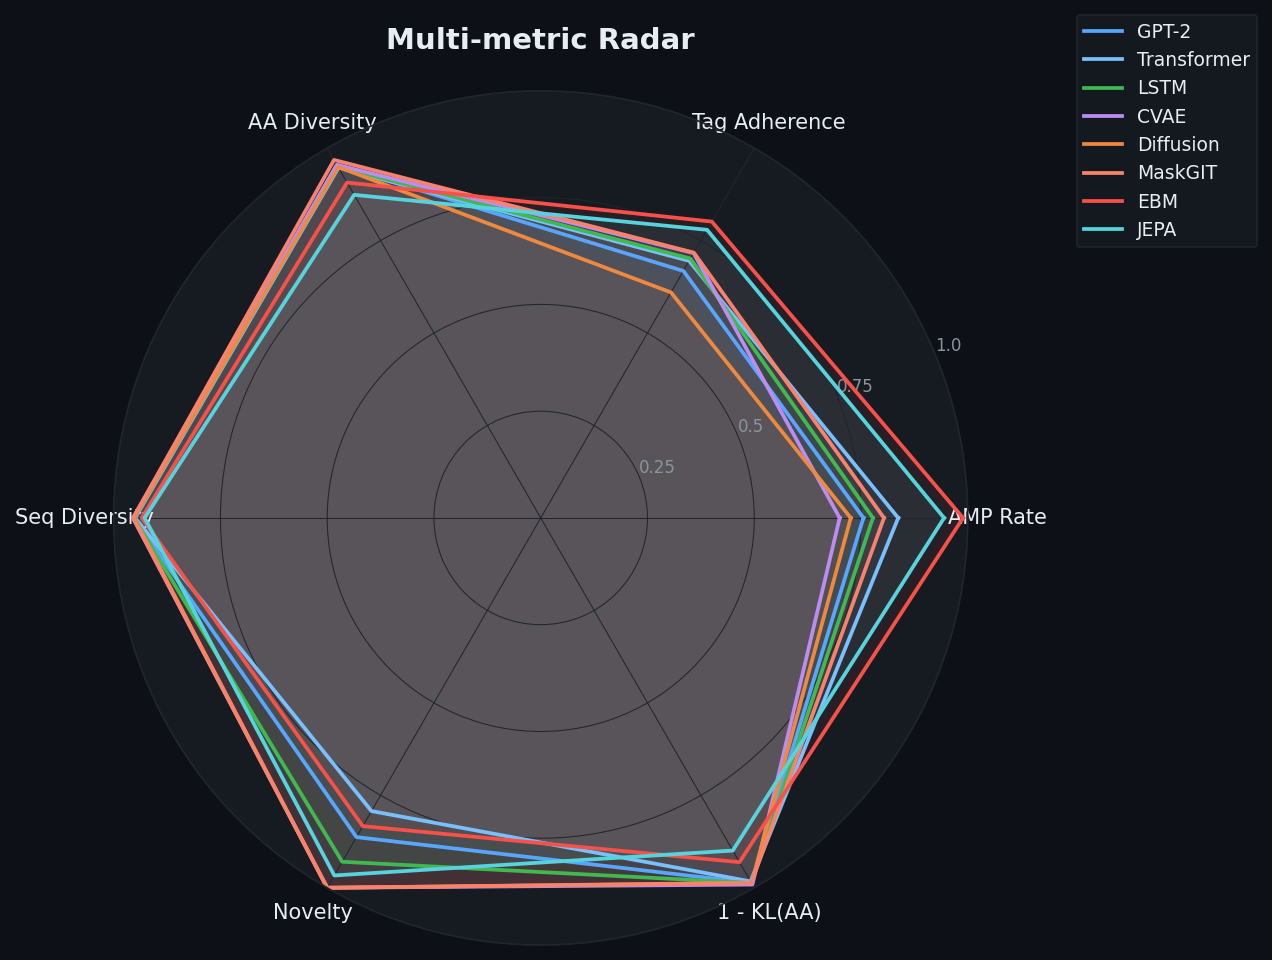

In [34]:
# pick key metrics for radar
radar_metrics = {
    'AMP Rate': {},
    'Tag Adherence': {},
    'AA Diversity': {},
    'Seq Diversity': {},
    'Novelty': {},
    '1 - KL(AA)': {},
}

for name in MODEL_NAMES:
    radar_metrics['AMP Rate'][name] = tier1[name]['AMP Hit Rate']
    radar_metrics['Tag Adherence'][name] = tier2[name]['Mean Tag Adherence']
    radar_metrics['AA Diversity'][name] = tier4[name]['AA Entropy']
    radar_metrics['Seq Diversity'][name] = tier4[name]['Seq Diversity']
    radar_metrics['Novelty'][name] = tier4[name]['Novelty Rate']
    # invert KL so higher = better
    kl = tier3[name]['KL AA vs Real']
    radar_metrics['1 - KL(AA)'][name] = max(0, 1 - kl)

categories = list(radar_metrics.keys())
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
ax.set_facecolor(CARD_BG)

for name in MODEL_NAMES:
    values = [radar_metrics[c][name] for c in categories] + [radar_metrics[categories[0]][name]]
    color = MODEL_COLORS[name]
    ax.plot(angles, values, color=color, linewidth=1.8, label=name)
    ax.fill(angles, values, color=color, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10, color=TEXT)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0.25', '0.5', '0.75', '1.0'], fontsize=8, color=TEXT_DIM)
ax.spines['polar'].set_color(GRID)
ax.grid(color=GRID, linewidth=0.5)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)
ax.set_title('Multi-metric Radar', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('radar_full.png', dpi=300, bbox_inches='tight', facecolor=DARK_BG)
plt.show()

### 8f. Metric bars (horizontal, grouped)

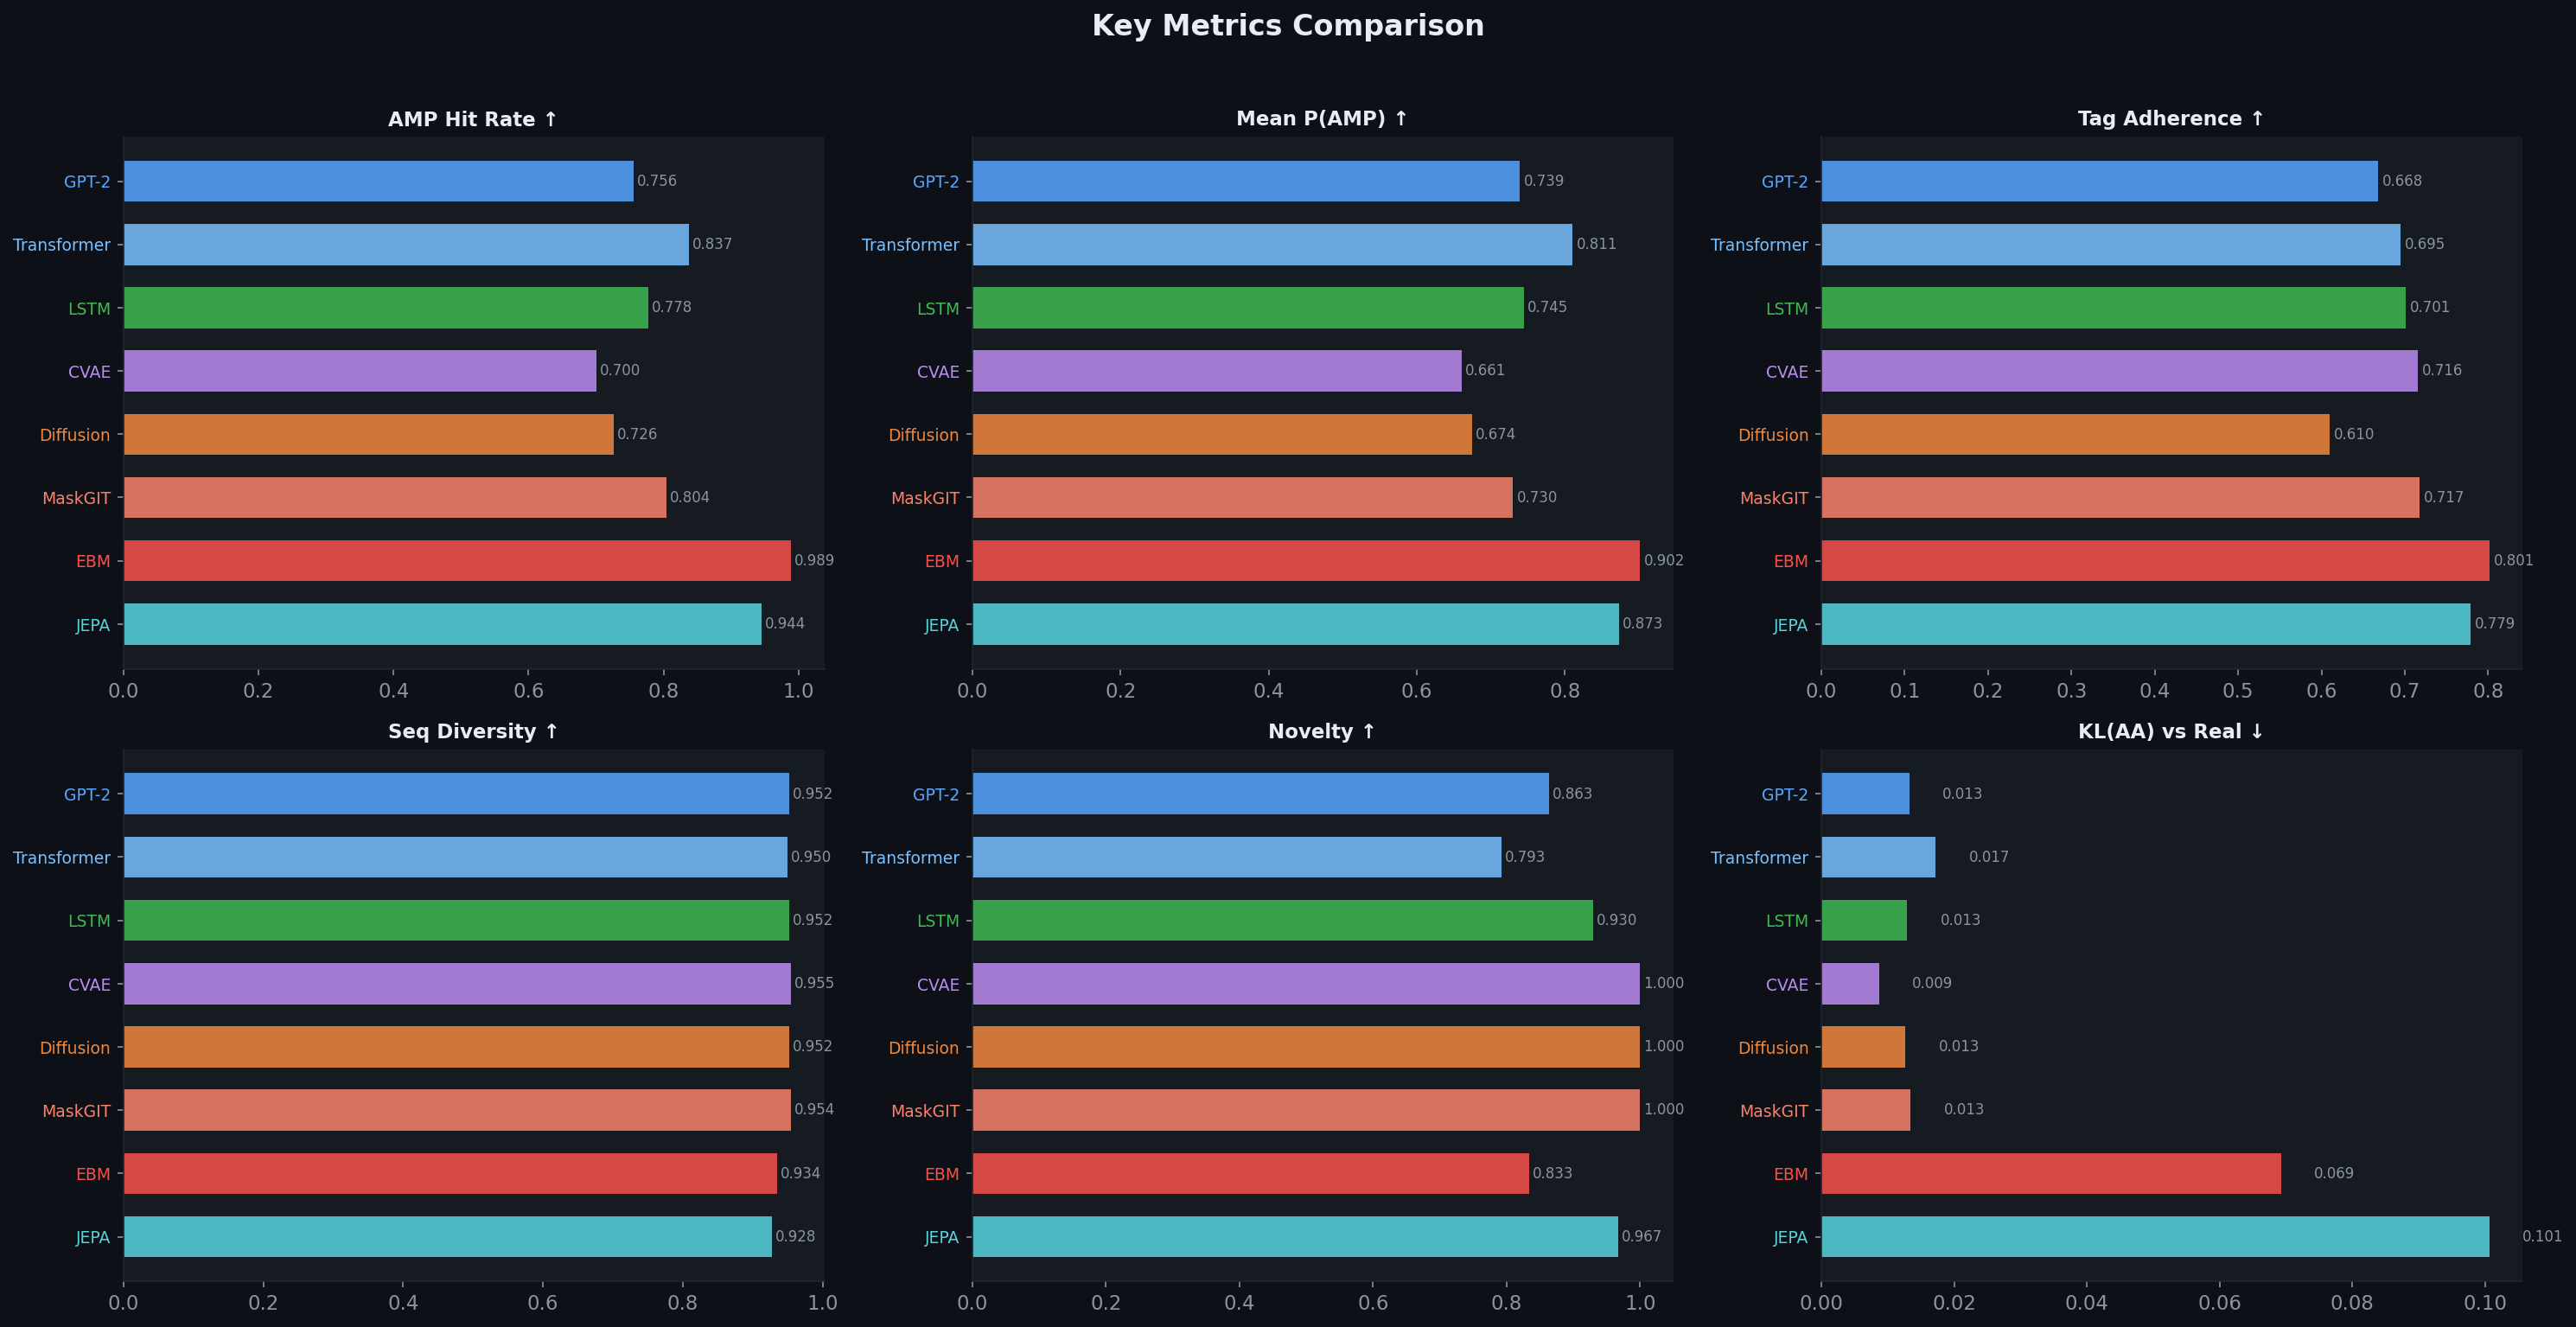

In [35]:
key_metrics = {
    'AMP Hit Rate ↑':      {m: tier1[m]['AMP Hit Rate'] for m in MODEL_NAMES},
    'Mean P(AMP) ↑':       {m: tier3[m]['Mean P(AMP)'] for m in MODEL_NAMES},
    'Tag Adherence ↑':     {m: tier2[m]['Mean Tag Adherence'] for m in MODEL_NAMES},
    'Seq Diversity ↑':     {m: tier4[m]['Seq Diversity'] for m in MODEL_NAMES},
    'Novelty ↑':           {m: tier4[m]['Novelty Rate'] for m in MODEL_NAMES},
    'KL(AA) vs Real ↓':    {m: tier3[m]['KL AA vs Real'] for m in MODEL_NAMES},
}

fig, axes = plt.subplots(2, 3, figsize=(20, 10))

for ax, (title, values_dict) in zip(axes.flat, key_metrics.items()):
    models = list(values_dict.keys())
    vals = [values_dict[m] for m in models]
    colors = [MODEL_COLORS[m] for m in models]

    bars = ax.barh(range(len(models)), vals, color=colors, alpha=0.85, height=0.65)
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(models, fontsize=9)
    for i, m in enumerate(models):
        ax.get_yticklabels()[i].set_color(MODEL_COLORS[m])
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for bar, val in zip(bars, vals):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
               f'{val:.3f}', va='center', fontsize=8, color=TEXT_DIM)

fig.suptitle('Key Metrics Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('key_metrics_bars.png', dpi=300, bbox_inches='tight', facecolor=DARK_BG)
plt.show()

## 9. Final scorecard — complete model comparison

All metrics in one table, best per column highlighted.

In [36]:
# merge all tiers
final_rows = []
for name in MODEL_NAMES:
    row = {'Model': name}
    # Tier 1
    row['AMP Hit Rate'] = tier1[name]['AMP Hit Rate']
    row['Valid AA'] = tier1[name]['Valid AA Rate']
    # Tier 2
    row['Len Match'] = tier2[name].get('Length Match', np.nan)
    row['Chg Match'] = tier2[name].get('Charge Match', np.nan)
    row['Hyd Match'] = tier2[name].get('Hydrophobicity Match', np.nan)
    row['Mean Adh'] = tier2[name].get('Mean Tag Adherence', np.nan)
    # Tier 3
    row['Mean P(AMP)'] = tier3[name]['Mean P(AMP)']
    row['P>0.8'] = tier3[name]['P(AMP) > 0.8']
    row['KL(AA)'] = tier3[name]['KL AA vs Real']
    row['KL(2mer)'] = tier3[name]['KL Bigram vs Real']
    row['Pos JS'] = pos_div[name]['Mean Pos JS']
    # Tier 4
    row['AA Ent'] = tier4[name]['AA Entropy']
    row['Seq Div'] = tier4[name]['Seq Diversity']
    row['Unique'] = tier4[name]['Unique Frac']
    row['Novelty'] = tier4[name]['Novelty Rate']
    final_rows.append(row)

final_df = pd.DataFrame(final_rows).set_index('Model')

# higher is better
higher_better = ['AMP Hit Rate', 'Valid AA', 'Len Match', 'Chg Match', 'Hyd Match',
                  'Mean Adh', 'Mean P(AMP)', 'P>0.8', 'AA Ent', 'Seq Div', 'Unique', 'Novelty']
# lower is better
lower_better = ['KL(AA)', 'KL(2mer)', 'Pos JS']


def highlight(s):
    if s.name in higher_better:
        best = s.max()
        return ['font-weight: bold; color: #3FB950' if v == best else '' for v in s]
    elif s.name in lower_better:
        best = s.min()
        return ['font-weight: bold; color: #3FB950' if v == best else '' for v in s]
    return ['' for _ in s]


styled = final_df.style.apply(highlight).format({
    c: '{:.3f}' for c in final_df.columns
})
styled

,AMP Hit Rate,Valid AA,Len Match,Chg Match,Hyd Match,Mean Adh,Mean P(AMP),P>0.8,KL(AA),KL(2mer),Pos JS,AA Ent,Seq Div,Unique,Novelty
Model,,,,,,,,,,,,,,,
GPT-2,0.756,1.000,0.533,0.693,0.778,0.668,0.739,0.589,0.013,0.073,0.135,0.955,0.952,0.989,0.863
Transformer,0.837,1.000,0.544,0.722,0.819,0.695,0.811,0.715,0.017,0.093,0.152,0.947,0.950,0.952,0.793
LSTM,0.778,1.000,0.570,0.748,0.785,0.701,0.745,0.611,0.013,0.070,0.140,0.950,0.952,0.993,0.930
CVAE,0.700,1.000,0.611,0.719,0.819,0.716,0.661,0.433,0.009,0.069,0.144,0.955,0.955,1.000,1.000
Diffusion,0.726,1.000,0.796,0.459,0.574,0.610,0.674,0.463,0.013,0.102,0.160,0.949,0.952,1.000,1.000
MaskGIT,0.804,1.000,0.693,0.685,0.774,0.717,0.730,0.530,0.013,0.073,0.157,0.968,0.954,1.000,1.000
EBM,0.989,1.000,1.000,0.707,0.696,0.801,0.902,0.800,0.069,0.323,0.252,0.907,0.934,0.833,0.833
JEPA,0.944,1.000,1.000,0.630,0.707,0.779,0.873,0.767,0.101,0.302,0.239,0.874,0.928,0.989,0.967


## 10. Export

In [37]:
final_df.to_csv('model_comparison_full.csv')
print('Saved: model_comparison_full.csv')
print()

# print a compact text summary
print('=' * 80)
print('MODEL RANKING (weighted composite score)')
print('=' * 80)

# composite: 40% AMP quality + 30% tag adherence + 20% diversity + 10% novelty
composite = {}
for name in MODEL_NAMES:
    amp_score = tier1[name]['AMP Hit Rate']
    adh_score = tier2[name].get('Mean Tag Adherence', 0)
    div_score = tier4[name]['Seq Diversity']
    nov_score = tier4[name]['Novelty Rate']
    composite[name] = 0.4 * amp_score + 0.3 * adh_score + 0.2 * div_score + 0.1 * nov_score

ranked = sorted(composite.items(), key=lambda x: x[1], reverse=True)
for rank, (name, score) in enumerate(ranked, 1):
    amp_r = tier1[name]['AMP Hit Rate']
    adh_r = tier2[name].get('Mean Tag Adherence', 0)
    print(f'  {rank}. {name:15s}  composite={score:.3f}  '
          f'(AMP={amp_r:.2f}, Adh={adh_r:.2f}, Div={tier4[name]["Seq Diversity"]:.2f}, Nov={tier4[name]["Novelty Rate"]:.2f})')

print()
print('Figures saved: amp_probability_violins.png, tag_adherence_heatmap.png,')
print('  basic_vs_acidic_scatter.png, cysteine_distribution.png,')
print('  radar_full.png, key_metrics_bars.png')

Saved: model_comparison_full.csv

MODEL RANKING (weighted composite score)
  1. EBM              composite=0.906  (AMP=0.99, Adh=0.80, Div=0.93, Nov=0.83)
  2. JEPA             composite=0.894  (AMP=0.94, Adh=0.78, Div=0.93, Nov=0.97)
  3. MaskGIT          composite=0.828  (AMP=0.80, Adh=0.72, Div=0.95, Nov=1.00)
  4. Transformer      composite=0.813  (AMP=0.84, Adh=0.70, Div=0.95, Nov=0.79)
  5. LSTM             composite=0.805  (AMP=0.78, Adh=0.70, Div=0.95, Nov=0.93)
  6. CVAE             composite=0.786  (AMP=0.70, Adh=0.72, Div=0.95, Nov=1.00)
  7. GPT-2            composite=0.779  (AMP=0.76, Adh=0.67, Div=0.95, Nov=0.86)
  8. Diffusion        composite=0.764  (AMP=0.73, Adh=0.61, Div=0.95, Nov=1.00)

Figures saved: amp_probability_violins.png, tag_adherence_heatmap.png,
  basic_vs_acidic_scatter.png, cysteine_distribution.png,
  radar_full.png, key_metrics_bars.png
